## Задание 3: Обновление информации о пользователе

Выполнил: Ларюшкин Кирилл Александрович

Группа: 292605


```bash
python -m venv venv
venv\Scripts\activate
pip install requests
pip freeze > requirements.txt
```

In [10]:
import requests  # Импорт модуля request
import logging  # Импорт модуля logging


# Настройка логирования
logging.basicConfig(
    filename='task3.log',  # Файл куда сохранять логи
    filemode='w',  # Режим - перезаписывать файл с логами при запуске
    level=logging.DEBUG,  # Определениение уровня логирования - уровень логирования DEBUG и выше
    format='%(asctime)s - %(levelname)s - %(message)s',  # Формат логов
    encoding='UTF-8',  # Кодировка UTF-8 , для корректного отображения кириллицы 
)


def authorization(data: dict):
    """ Фунция авторизации пользователя
    Отправляет пост запрос на 'https://dummyjson.com/user/login' с данными :заголовок с форматом данных, логин, пароль, время действия токена
    Производить авторизацию пользователя и возвращает результат ответа в виде user_id и token
    """

    try:
        logging.info(f'Авторизация пользователя {data["username"]}. Обращение к API ...')  # Логирование обращения к API
        
        url = 'https://dummyjson.com/user/login'  # URL ручки авториазции
        headers = { 'Content-Type': 'application/json' }  # заголовок с типом передаваемых данных
        
        response = requests.post(url, headers=headers, json=data, timeout=10)  # POST запрос с данными и тайм-аутом
        response.raise_for_status()  # контролируем статус-код ответа, в случае ошибки обрабатываем исключение
        
        result = response.json()  # преобразуем ответ в словарь
    
        user_id = result['id']  # получаем из ответа id пользователя
        token = result['accessToken']  # получаем из ответа токен пользователя
    
        print('Авторизация прошла успешно')  # сообщение пользователю о результате авторизации
        print('Ваш ID:', user_id)  # сообщение пользователю с его id
    
        return user_id, token  # возвращаем id и токен, токен нигде не логируем и не отображем в целях безопасности
        
    except requests.exceptions.HTTPError as e: # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        logging.error('Ошибка авторизации пользователя')  # Логирует ошибку
        return (f'Неверно введен логин или пароль, либо данного пользователя не существует: {e}')  # Вывод сообщения ошибки
    
    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        logging.error(f'Произошла ошибка при соединении: {e}')  # Логирует ошибку
        return f'Произошла ошибка при соединении: {e}' # Вывод сообщения ошибки

    except requests.exceptions.JSONDecodeError as e:  # Обрабатывает ошибки при преобразовании в JSON
        logging.error(f'Ошибка декодирования JSON: {e}')  # Логирует ошибку
        return f'Сервер вернул некорректные данные: {e}'  # Вывод сообщения ошибки

    except (KeyError, ValueError, TypeError) as e:  # Ловим ошибки при обработке данных
        logging.error(f'Ошибка обработки ответа сервера: {e}')  # Логирует ошибку
        return f'Ошибка обработки ответа сервера: {e}'  # Вывод сообщения ошибки


def editing_login(edit_data: str, user_id: int, token: str):
    """ Функция редактирования параметров Фамилии, Имя, Пароль 
    Принимает аргументы: edit_data - редактируемый обьект, user_id - id пользователя, token - токен
    В зависимости от желаемых данных, которые пользователь хочет отредактировать, предлагает ввести новое значение
    Отправляет PUT запрос на https://dummyjson.com/users/{user_id} и обновляет данные
    Выводит сообщение с результатом какие данные обновлены и новое значение
    """

    try:
        url = f'https://dummyjson.com/users/{user_id}'  # URL конкрутного пользователя по его id
        
        # Заголовок с типом данных и токеном
        headers = { 
            'Content-Type': 'application/json',
            'Authorization': f'Bearer {token}'
        }

        # Ветвление для выбора параметра который будем редактировать
        if edit_data == 'фамилия':
            # Словарь с новыми данными фамилии и запросом их указать
            data = {
                'lastName': input('Введите новую фамилию: ').strip()
            }
            
            logging.info(f'Пользователь обновляет Фамилию на {data["lastName"]} ')  # Логирование новых данных

        elif edit_data == 'имя':
            # Словарь с новыми данными имени и запросом их указать
            data = {
                'firstName': input('Введите новое имя: ').strip()
            }
            logging.info(f'Пользователь обновляет Имя на {data["firstName"]} ')  # Логирование новых данных
        
        elif edit_data == 'пароль':
            # Словарь с новыми данными пароля и запросом их указать
            data = {
                'password': input('Введите новый пароль: ').strip()
            }
            logging.info('Пользователь изменяет пароль') # Логирование новых данных
        else:
            logging.info(f'Пользователь ввел некорректное поле для редактирования - {edit_data} ')  # Логирование ошибки
            # Возвращаем сообщение пользователю при некорректном выборе поля редактирования
            return (
                'Неизвестное поле для редактирования.\n'
                'Доступные поля: имя, фамилия, пароль.'
            )


        
        logging.info(f'Обновление данных пользователя. Обращение к API ...')  # Логирование обращения к API
        
        new_field = next(iter(data), None)  # Делаем интерацию по data и выбираем первый ключ словаря с помощью next и сохраняем в new_field
        response = requests.put(url, headers=headers, json=data, timeout=10)  # PUT запрос с передачей новых данных и тайм-аутом
        response.raise_for_status()  # Контролируем статус-код ответа, в случае ошибки обрабатываем исключение
            
        result = response.json()  # Преобразуем ответ в словарь

        logging.info(f'Запрос обновления данных выполнен успешно. Данные в разделе {edit_data} обновлены.\nНовые данные: {result[new_field]}')  # Логируем результаты обращения к API
        
        return f'Данные в разделе {edit_data} обновлены.\nНовые данные: {result[new_field]}'  # Возвращаем сообщение с результатом и новыми данными 
        
    
    except requests.exceptions.HTTPError as e:  # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        logging.error(f'Ошибка при редактировании пользователя: {e}')  # Логирует ошибку
        return f'Сервер вернул ошибку при редактировании пользователя: {e}'  # Вывод сообщения ошибки

    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        logging.error(f'Ошибка соединения при редактировании: {e}')  # Логирует ошибку
        return f'Не удалось связаться с сервером при редактировании: {e}'  # Вывод сообщения ошибки

    except requests.exceptions.JSONDecodeError as e:  # Обрабатывает ошибки при преобразовании в JSON
        logging.error(f'Ошибка декодирования JSON: {e}')  # Логирует ошибку
        return f'Сервер вернул некорректные данные: {e}'  # Вывод сообщения ошибки

    except (KeyError, ValueError, TypeError) as e:  # Ловим ошибки при обработке данных
        logging.error(f'Ошибка обработки ответа сервера: {e}')  # Логирует ошибку
        return f'Ошибка обработки данных: {e}'  # Вывод сообщения ошибки


def check_users(user_id: int):
    """ Функция поиска информации пользователей
    Принимает id искомого пользователя
    Делает get запрос на https://dummyjson.com/users/{user_id}
    Выводит информацию о пользователе : ID - Имя - Фамилию - Возраст
    """
    
    try :
        user_id = int(user_id)
        # Условие - если пользователь ввел id 0 или меньше то выводим сообщение что число должно быть положительным
        if user_id <= 0:
            return 'ID пользователя должен быть положительным числом'
            
        logging.info(f'Поиск пользователя с id - {user_id}. Обращение к API ...')  # Логирование  обращения к API
        
        url = f'https://dummyjson.com/users/{user_id}'  # URL конкретного пользователя. в жанном случае искокомого
        response = requests.get(url, timeout=10)  # GET запрос на получение данных пользователя с тайм-аутом
        
        if response.status_code == 404:
            logging.info(f'Обращение выполнено успешно. Пользователь не найден.')  # Результат обращения
            return f'Пользователь не найден'
    
        else:
            response.raise_for_status()  # Контролируем статус-код ответа, в случае ошибки обрабатываем исключе
            
            result = response.json()  # Преобразуем ответ в словарь
            
            logging.info(f'Обращение выполнено успешно. Пользователь найден.')  # Результат обращения
            
            return f'ID: {result["id"]} - Имя: {result["firstName"]} - Фамилия: {result["lastName"]} - Возраст: {result["age"]}'  # Возвращаем информацию о искомом пользователе

        
    except requests.exceptions.HTTPError as e:  # Обрабатывает случай, когда запрос был успешно отправлено сервер его обработал, но вернул статус-код указывающий на ошибку
        logging.error(f'Ошибка при обращении к данным пользователя: {e}')  # Логирует ошибку
        return f'Сервер вернул ошибку при обращении к данным пользователя: {e}'  # Вывод сообщения ошибки

    except requests.exceptions.RequestException as e:  # Обрабатывает ошибки при обращении к API
        logging.error(f'Ошибка соединения при обращении к данным пользователя: {e}')  # Логирует ошибку
        return f'Не удалось связаться с сервером при обращении к данным пользователя: {e}'  # Вывод сообщения ошибки
        
    except requests.exceptions.JSONDecodeError as e:  # Обрабатывает ошибки при преобразовании в JSON
        logging.error(f'Ошибка декодирования JSON: {e}')  # Логирует ошибку
        return f'Сервер вернул некорректные данные: {e}'  # Вывод сообщения ошибки

    except ValueError as e:  # Ловим ошибки при обработке данных
        logging.error(f'Ошибка обработки ответа сервера: {e}')  # Логирует ошибку
        return f'Ошибка обработки данных: {e}.\nПожалуйста введите id пользователя целым числом'  # Вывод сообщения ошибк


    
# Реализация пользовательского интерфейса для удобства
user_id = None
token = None

while True:
    
        # Пользовательский ввод
        user_input = input('Введите номер действия, что хотите выполнить:\n 1) Авторизироваться \n 2) Обновить данные(например фамилию)\n 3) Получение данных пользователя\n 4) Для выхода введите "q" ').strip()

        # Условное ветвление
        if user_input == '1':
            logging.info(f'Пользователь ввел {user_input} и выбрал Авторизация')  # Логирование действий пользователя
            # Пользователь выбрал пункт 1 - Авторизация

            # Данные пользователя
            data = {
                'username': input('Введите логин (например emilys)').strip(),  # Логин
                'password': input('Введите пароль (например emilyspass)').strip(),  # Пароль
                'expiresInMins': 30  # Сколько держать токен в минутах
            }

            result = authorization(data)  # вызов функции и сохранение результата в переменную result

            # Если ответ авторизации корректный, то сохраняем токен и id пользователя
            if isinstance(result, tuple):
                user_id, token = result  # Вызов функции с пердачей данных продукта
                logging.info(f'Авторизация прошла успешно')  # Логирование результата авторизации
                logging.info(f'ID пользователя: {user_id}')  # Логирование ID пользователя
            else :
                print(result)
    
        elif user_input == '2':
            # Пользователь выбрал пункт 2 - Обновить данные
            logging.info(f'Пользователь с id - {user_id} выбрал Обновить данные ')  # Логирование действий пользователя

            # Проверка, авторизирован ли пользователь, если нет, выводим сообщение
            if user_id is None or token is None:
                print('Вы не авторизированы. Для начала необходимо авторизоваться - раздел 1')  # Сообщение с просьбой авторизироваться перед редактированием профиля
                continue  # Продолжаем работу програмы, возращаемся в начало
            
            edit_data = input('Введите что хотите обновить( например Имя, Фамилия или Пароль): ').strip().lower()  # Пользовательский ввод данных которые он хочет обновить, убираем пробелы и делаем в нижний регистр
            
            logging.info(f'Пользователь обновляет {edit_data} ')  # логирование действий пользователя
            
            print(editing_login(edit_data, user_id, token))  # Вызов функции редактирования с пердачей параметра который обновляется, id пользователя и токена
            
        elif user_input == '3':
            # Пользователь выбрал пункт 3 - 
            found_user_id = input(f'Введите id пользователя для получения информации он нем (ваш id - {user_id if user_id else "Вы не авторизированы"}): ').strip().lower()   # Пользовательский ввод id продукта для проверки наличия и получения данных
        
            logging.info(f'Пользователь ввел {user_input} и выбрал Получение данных пользователя с id {found_user_id}')  # логирование действий пользователя
            print(check_users(found_user_id))  # Вызов функции с пердачей id продукта
            
        elif user_input == 'q':
            print('Работа программы завершена')  # Выводит информацию по завершению программы
            logging.info('Работа программы завершена')  # Логируем завершение программы
            break  # Завершаем работу программы
            
        else:
            logging.info(f'Пользователь ввел {user_input}. Некорректный ввод')  # Логирование действий пользователя
            print('Некорректый ввод. Введите номер действия в виде цифры (1,2,3), а что бы выйти введите "q"') # Вывод сообщения при некорректном вводе от пользователя



Введите номер действия, что хотите выполнить:
 1) Авторизироваться 
 2) Обновить данные(например фамилию)
 3) Получение данных пользователя
 4) Для выхода введите "q"                                     1
Введите логин (например emilys)                   sdf
Введите пароль (например emilyspass)                          sdf


Неверно введен логин или пароль, либо данного пользователя не существует: 400 Client Error: Bad Request for url: https://dummyjson.com/user/login


Введите номер действия, что хотите выполнить:
 1) Авторизироваться 
 2) Обновить данные(например фамилию)
 3) Получение данных пользователя
 4) Для выхода введите "q"                       1
Введите логин (например emilys)                emilys     
Введите пароль (например emilyspass)                emilyspass


Авторизация прошла успешно
Ваш ID: 1


Введите номер действия, что хотите выполнить:
 1) Авторизироваться 
 2) Обновить данные(например фамилию)
 3) Получение данных пользователя
 4) Для выхода введите "q"                                2
Введите что хотите обновить( например Имя, Фамилия или Пароль):               sdf


Неизвестное поле для редактирования.
Доступные поля: имя, фамилия, пароль.


... (22 outputs left out)

Введите номер действия, что хотите выполнить:
 1) Авторизироваться 
 2) Обновить данные(например фамилию)
 3) Получение данных пользователя
 4) Для выхода введите "q"  235


Некорректый ввод. Введите номер действия в виде цифры (1,2,3), а что бы выйти введите "q"


Введите номер действия, что хотите выполнить:
 1) Авторизироваться 
 2) Обновить данные(например фамилию)
 3) Получение данных пользователя
 4) Для выхода введите "q"              q


Работа программы завершена


```bash
deactivate
```

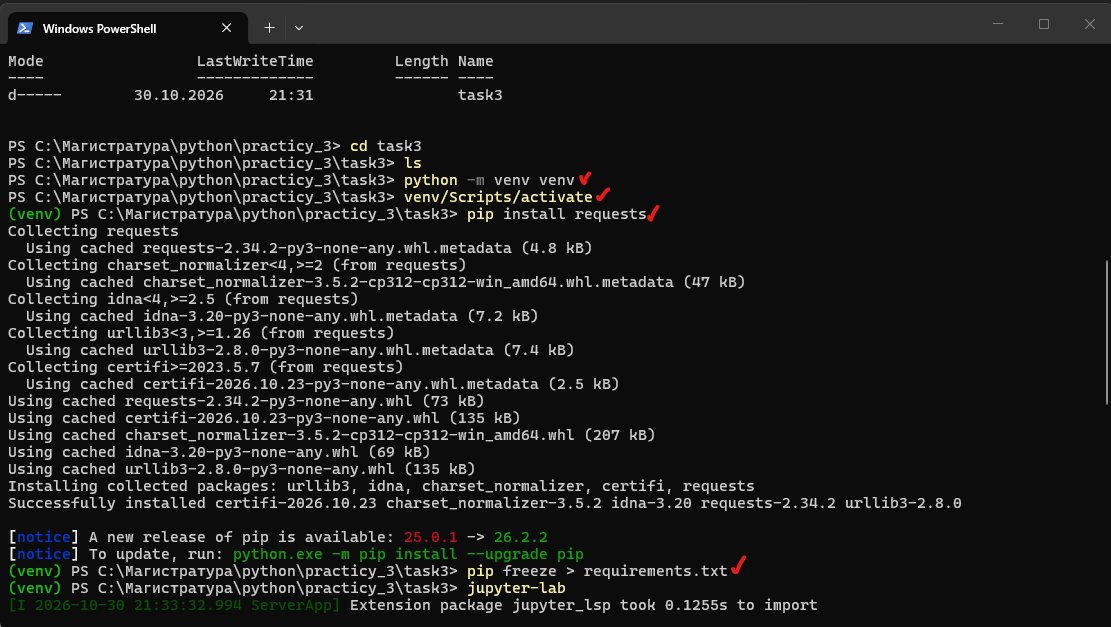

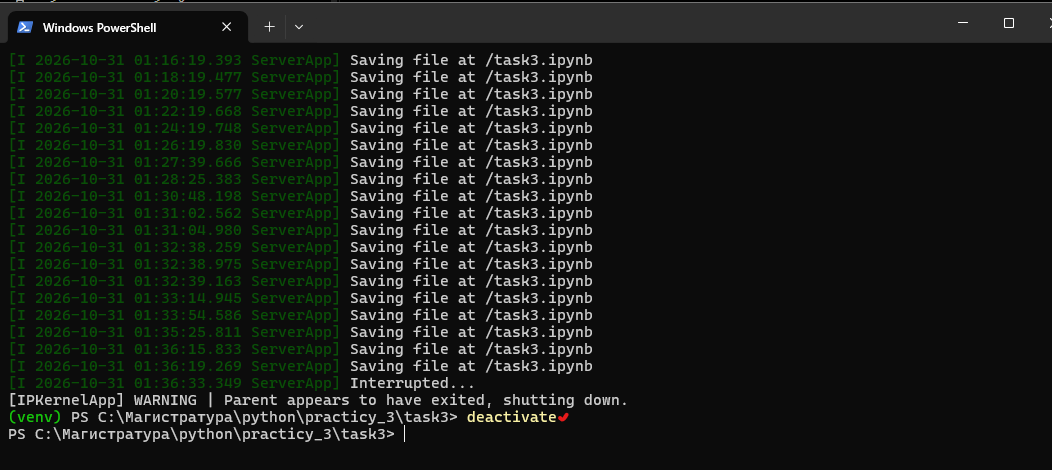